# Charles River Streamflow — MLP Practice Project

**Goal:** predict next-day daily mean discharge (cfs) at USGS Waltham gauge `01104500` and evaluate whether past weather improves prediction beyond past streamflow. This is a **practice analysis**, not a claim of an operational flood forecast.

**Inputs:** `daily_merged.csv` from the shared cleaned dataset, USGS discharge + NOAA Boston Logan weather. Use data from **1990-01-01 to 2025-12-31** (exclude provisional 2026). The prediction for day *t* uses discharge and observed weather only from days *t−1 ... t−7*, plus calendar information known for day *t*. Thus no future observed weather leaks into the forecast.

**Comparison:** persistence baseline, flow-only MLP, flow + weather MLP. Time splits: training through 2016, validation 2017–2020, test 2021–2025. One frozen test set. Models have comparable architecture and training settings. MAE/RMSE are in cfs.


In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 4420
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DATA_PATH = Path('daily_merged.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('/mnt/data/daily_merged.csv')
assert DATA_PATH.exists(), 'Put daily_merged.csv next to this notebook.'
print('PyTorch', torch.__version__, '| file:', DATA_PATH)


PyTorch 2.10.0+cpu | file: daily_merged.csv


## 1. Dataset checks

NOAA weather comes from Logan rather than the full Charles River watershed. Precipitation is a proxy, not complete catchment precipitation. The merged data documentation notes estimated discharge on some winter days; keep these for the primary practice model but check sensitivity in future work.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['date']).sort_values('date').reset_index(drop=True)
assert not df['date'].duplicated().any()
assert (df['date'].diff().dropna() == pd.Timedelta(days=1)).all()
print('Full merged table:', df.shape, df.date.min().date(), df.date.max().date())
print('Qualifiers:', df['discharge_qualifier'].value_counts(dropna=False).head())
print('Recent approvals:', df['discharge_approval'].value_counts(dropna=False).to_dict())
use = df[df.date.between('1990-01-01','2025-12-31')].copy()
print('Selected:', use.shape)
print(use[['discharge_cfs_mean','precip_in','tmean_f','snowfall_in']].isna().sum())


Full merged table: (34805, 19) 1931-08-04 2026-11-17
Qualifiers: discharge_qualifier
NaN          34747
ESTIMATED       58
Name: count, dtype: int64
Recent approvals: {'Approved': 34642, 'Provisional': 163}
Selected: (13149, 19)
discharge_cfs_mean    0
precip_in             2
tmean_f               0
snowfall_in           0
dtype: int64


## 2. Causal feature engineering

The target on date *t* is flow on that date. For each lag k=1,...,7, `flow_lag_k`, `precip_lag_k`, `temp_lag_k`, and `snow_lag_k` refer to observations on t−k. `doy_sin`, `doy_cos` of the target date are allowed because the calendar date is known in advance. Missing historic NOAA readings are imputed with **training-only medians**. No future target values enter input features.

In [3]:
for k in range(1,8):
    for src,prefix in [('discharge_cfs_mean','flow'),('precip_in','precip'),('tmean_f','temp'),('snowfall_in','snow')]:
        use[f'{prefix}_lag_{k}'] = use[src].shift(k)
use = use.dropna(subset=[f'flow_lag_{k}' for k in range(1,8)]).copy()
flow_features = [f'flow_lag_{k}' for k in range(1,8)] + ['doy_sin','doy_cos']
weather_features = [f'{v}_lag_{k}' for v in ('precip','temp','snow') for k in range(1,8)]
all_features = flow_features + weather_features
train = use[use.date < '2017-01-01'].copy()
val = use[use.date.between('2017-01-01','2020-12-31')].copy()
test = use[use.date.between('2021-01-01','2025-12-31')].copy()
assert max(train.date) < min(val.date) < max(val.date) < min(test.date)
print('Train:',train.shape[0],train.date.min().date(),train.date.max().date())
print('Valid:',val.shape[0],val.date.min().date(),val.date.max().date())
print('Test: ',test.shape[0],test.date.min().date(),test.date.max().date())
print('Flow feature count',len(flow_features),'Weather-added feature count',len(all_features))


Train: 9855 1990-01-08 2016-12-31
Valid: 1461 2017-01-01 2020-12-31
Test:  1826 2021-01-01 2025-12-31
Flow feature count 9 Weather-added feature count 30


## 3. Standardize train-only, train the MLP

The MLP uses 2 ReLU hidden layers (32 and 16 units), linear output, Adam optimization and early stopping on **validation** loss. The regression target uses `log1p(flow)` during training to reduce the influence of occasional very high values; predictions are transformed back to cfs for evaluation. Scaling and missing-value imputation are fit on training data only.

PyTorch implements this model, so this **does not count as a manual implementation** of the neural network. The team's other method would need to meet any manual-implementation requirement.

In [4]:
def prepare(features):
    med = train[features].median().fillna(0)
    Xtrain0 = train[features].fillna(med)
    scaler = StandardScaler().fit(Xtrain0)
    def x(part):
        return torch.tensor(scaler.transform(part[features].fillna(med)),dtype=torch.float32)
    def y(part):
        return torch.tensor(np.log1p(part['discharge_cfs_mean'].to_numpy()), dtype=torch.float32).reshape(-1,1)
    return x(train),y(train),x(val),y(val),x(test),scaler,med

class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features,32),nn.ReLU(),
                                 nn.Linear(32,16),nn.ReLU(),nn.Linear(16,1))
    def forward(self,x): return self.net(x)

def train_model(features, max_epochs=140, patience=16):
    torch.manual_seed(SEED)
    Xt,yt,Xv,yv,Xe,scaler,med = prepare(features)
    model = MLP(len(features))
    opt = torch.optim.Adam(model.parameters(),lr=0.003,weight_decay=0.0001)
    criterion=nn.MSELoss()
    best=float('inf'); wait=0; best_state=None; losses=[]
    for epoch in range(max_epochs):
        model.train()
        ix = torch.randperm(len(Xt))
        for b in ix.split(512):
            opt.zero_grad()
            loss=criterion(model(Xt[b]),yt[b])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr=criterion(model(Xt),yt).item()
            va=criterion(model(Xv),yv).item()
        losses.append((tr,va))
        if va < best-1e-5:
            best=va; wait=0
            best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=patience:break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred=np.expm1(model(Xe).numpy().reshape(-1))
    pred=np.maximum(pred,0)
    return dict(model=model,pred=pred,losses=np.asarray(losses),scaler=scaler,medians=med,features=features)

flow_only=train_model(flow_features)
flow_weather=train_model(all_features)
print('Epochs flow-only:',len(flow_only['losses']))
print('Epochs weather-added:',len(flow_weather['losses']))


Epochs flow-only: 140
Epochs weather-added: 140


## 4. Test-set results and persistence baseline

Persistence uses yesterday's streamflow for today's forecast and is a strong benchmark for slow-moving rivers. Results below use *only* the final 2021–2025 test years. R² can be negative if a model underperforms predicting a constant test mean.

In [5]:
y_true=test['discharge_cfs_mean'].to_numpy()
preds={
    'Persistence (yesterday)':test['flow_lag_1'].to_numpy(),
    'MLP: flow + season':flow_only['pred'],
    'MLP: flow + weather + season':flow_weather['pred']
}
rows=[]
for name,pred in preds.items():
    rows.append({'Model':name,
                 'MAE (cfs)':mean_absolute_error(y_true,pred),
                 'RMSE (cfs)':np.sqrt(mean_squared_error(y_true,pred)),
                 'R²':r2_score(y_true,pred)})
results=pd.DataFrame(rows).sort_values('MAE (cfs)').reset_index(drop=True)
print(results.round(3).to_string(index=False))
print('Improvement in MAE from extra weather (positive=better):',round(mean_absolute_error(y_true,flow_only['pred'])-mean_absolute_error(y_true,flow_weather['pred']),3),'cfs')


                       Model  MAE (cfs)  RMSE (cfs)    R²
     Persistence (yesterday)     27.691      57.304 0.957
MLP: flow + weather + season     31.253      60.662 0.951
          MLP: flow + season     32.435      63.744 0.946
Improvement in MAE from extra weather (positive=better): 1.182 cfs


## 5. Figures: predictions and training dynamics

Show the **full test period** in muted lines, plus one illustrative 2023 window for legibility. Don't select a window based on favorable performance when describing conclusions. Export both figures as PNG.

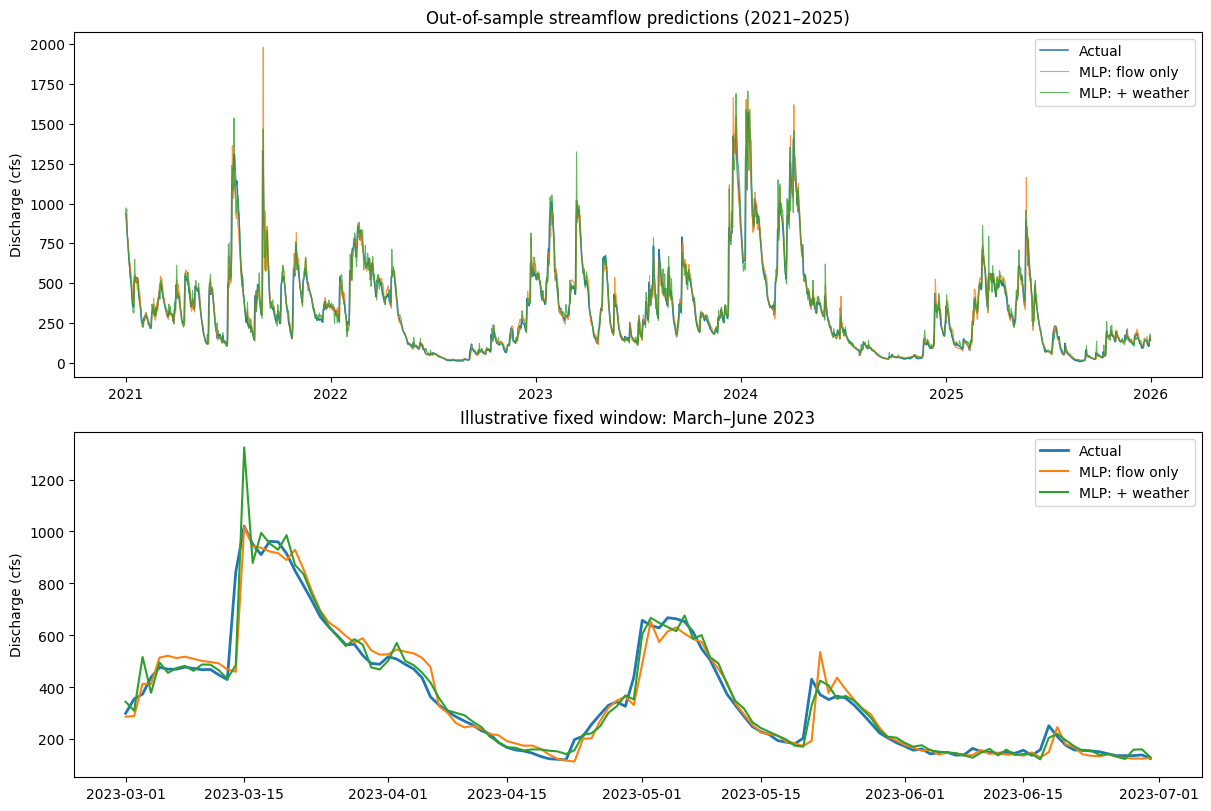

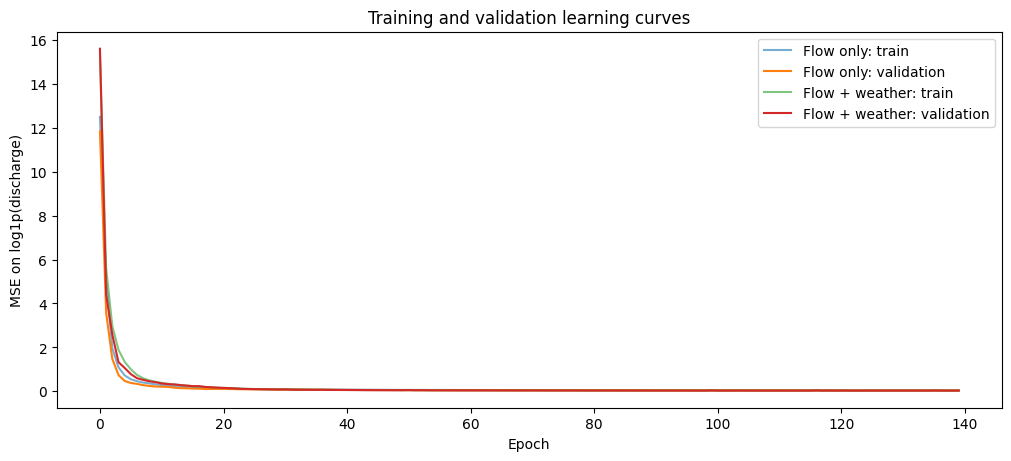

In [6]:
out_dir=Path('mlp_outputs'); out_dir.mkdir(exist_ok=True)
fig,axs=plt.subplots(2,1,figsize=(12,8),layout='constrained')
axs[0].plot(test.date,y_true,label='Actual',linewidth=1.1)
axs[0].plot(test.date,flow_only['pred'],label='MLP: flow only',alpha=.8,linewidth=.8)
axs[0].plot(test.date,flow_weather['pred'],label='MLP: + weather',alpha=.75,linewidth=.8)
axs[0].set_title('Out-of-sample streamflow predictions (2021–2025)')
axs[0].set_ylabel('Discharge (cfs)');axs[0].legend()
mask=test.date.between('2023-03-01','2023-06-30').to_numpy()
axs[1].plot(test.date[mask],y_true[mask],label='Actual',linewidth=2)
axs[1].plot(test.date[mask],flow_only['pred'][mask],label='MLP: flow only')
axs[1].plot(test.date[mask],flow_weather['pred'][mask],label='MLP: + weather')
axs[1].set_title('Illustrative fixed window: March–June 2023')
axs[1].set_ylabel('Discharge (cfs)');axs[1].legend()
fig.savefig(out_dir/'mlp_predictions.png',dpi=170,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
for name,obj in [('Flow only',flow_only),('Flow + weather',flow_weather)]:
    ax.plot(obj['losses'][:,0],label=f'{name}: train',alpha=.6)
    ax.plot(obj['losses'][:,1],label=f'{name}: validation')
ax.set_xlabel('Epoch');ax.set_ylabel('MSE on log1p(discharge)')
ax.set_title('Training and validation learning curves')
ax.legend()
fig.savefig(out_dir/'mlp_learning_curves.png',dpi=170,bbox_inches='tight')
plt.show()


## 6. High-flow diagnostic (optional)

Define *high-flow* as exceeding the **95th percentile of training-period daily discharge**. This is a statistical threshold, **not** an official flood-stage classification. Check whether predictions meet the threshold on true high-flow days; a low overall MAE can mask poor peak forecasting.

In [7]:
threshold=float(train['discharge_cfs_mean'].quantile(.95))
actual_high=y_true>=threshold
hi_rows=[]
for name,pred in preds.items():
    predicted_high=pred>=threshold
    tp=int((predicted_high & actual_high).sum())
    fp=int((predicted_high & ~actual_high).sum())
    fn=int((~predicted_high & actual_high).sum())
    hi_rows.append({'Model':name,'High-day MAE (cfs)':mean_absolute_error(y_true[actual_high],pred[actual_high]),
                    'Recall':tp/(tp+fn) if tp+fn else np.nan,
                    'Precision':tp/(tp+fp) if tp+fp else np.nan,
                    'Predicted high days':int(predicted_high.sum())})
high_results=pd.DataFrame(hi_rows)
print('Training-only high-flow threshold (95th pct):',round(threshold,2),'cfs')
print('True high days in test:',int(actual_high.sum()))
print(high_results.round(3).to_string(index=False))


Training-only high-flow threshold (95th pct): 886.0 cfs
True high days in test: 97
                       Model  High-day MAE (cfs)  Recall  Precision  Predicted high days
     Persistence (yesterday)              96.670   0.887      0.878                   98
          MLP: flow + season             116.997   0.825      0.899                   89
MLP: flow + weather + season             126.257   0.876      0.895                   95


## 7. Save results for collaboration

CSV outputs include test dates, observations and predictions; summary tables can support a report or cross-model comparison. **Re-run the notebook** if the shared data file is refreshed, and record the refresh version from `DATA.md`.

**Limitations:** one weather station may poorly represent rainfall upstream; strong serial correlation makes persistence difficult to beat; extreme-flow events are rare; target is mean daily discharge rather than flood stage; no hyperparameter search was conducted on test set; estimated winter and provisional rows need sensitivity analysis. There is no evidence here of operational flood-warning performance.

In [8]:
pred_table=pd.DataFrame({'date':test.date.to_numpy(), 'actual_cfs':y_true,
                         'persistence_cfs':preds['Persistence (yesterday)'],
                         'mlp_flow_only_cfs':flow_only['pred'],
                         'mlp_flow_weather_cfs':flow_weather['pred']})
pred_table.to_csv(out_dir/'mlp_test_predictions.csv',index=False)
results.to_csv(out_dir/'mlp_model_comparison.csv',index=False)
high_results.to_csv(out_dir/'mlp_high_flow_diagnostics.csv',index=False)
print('Saved:',*[str(x) for x in sorted(out_dir.iterdir())],sep='\n - ')


Saved:
 - mlp_outputs/mlp_high_flow_diagnostics.csv
 - mlp_outputs/mlp_learning_curves.png
 - mlp_outputs/mlp_model_comparison.csv
 - mlp_outputs/mlp_predictions.png
 - mlp_outputs/mlp_test_predictions.csv
